2021-22: 1519618 rows
2022-23: 1467738 rows
2023-24: 1471765 rows


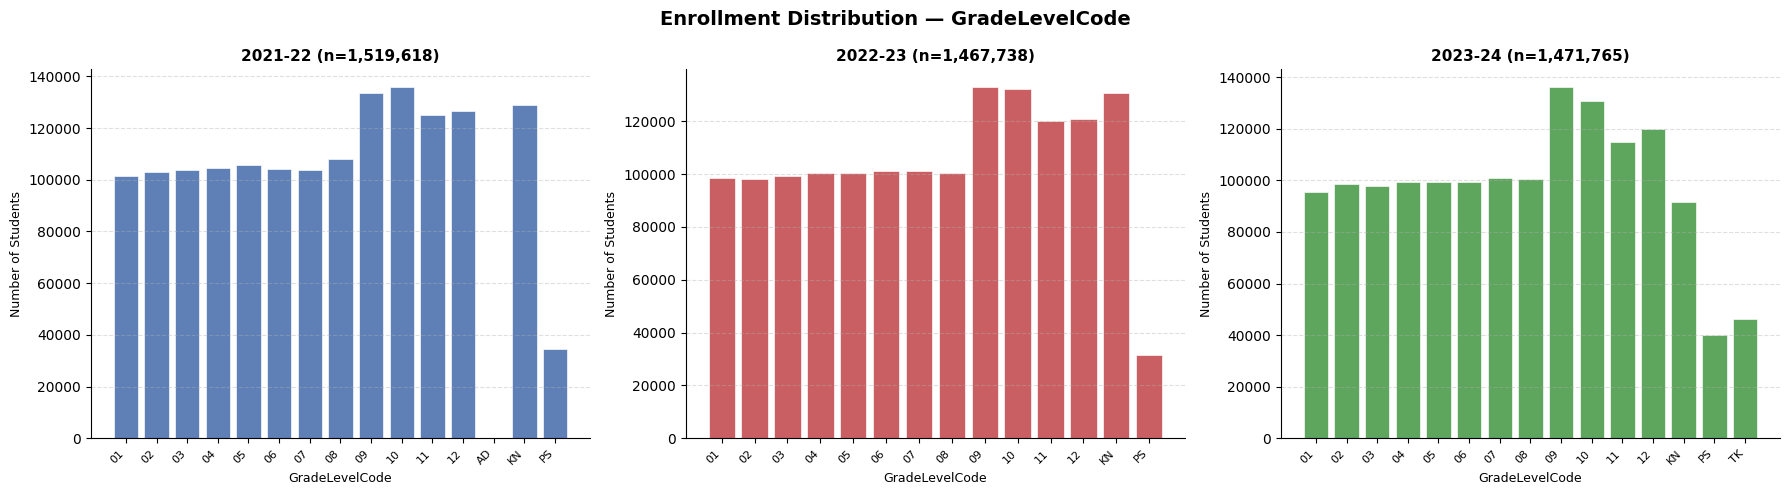

Saved enrollment_GradeLevelCode.png


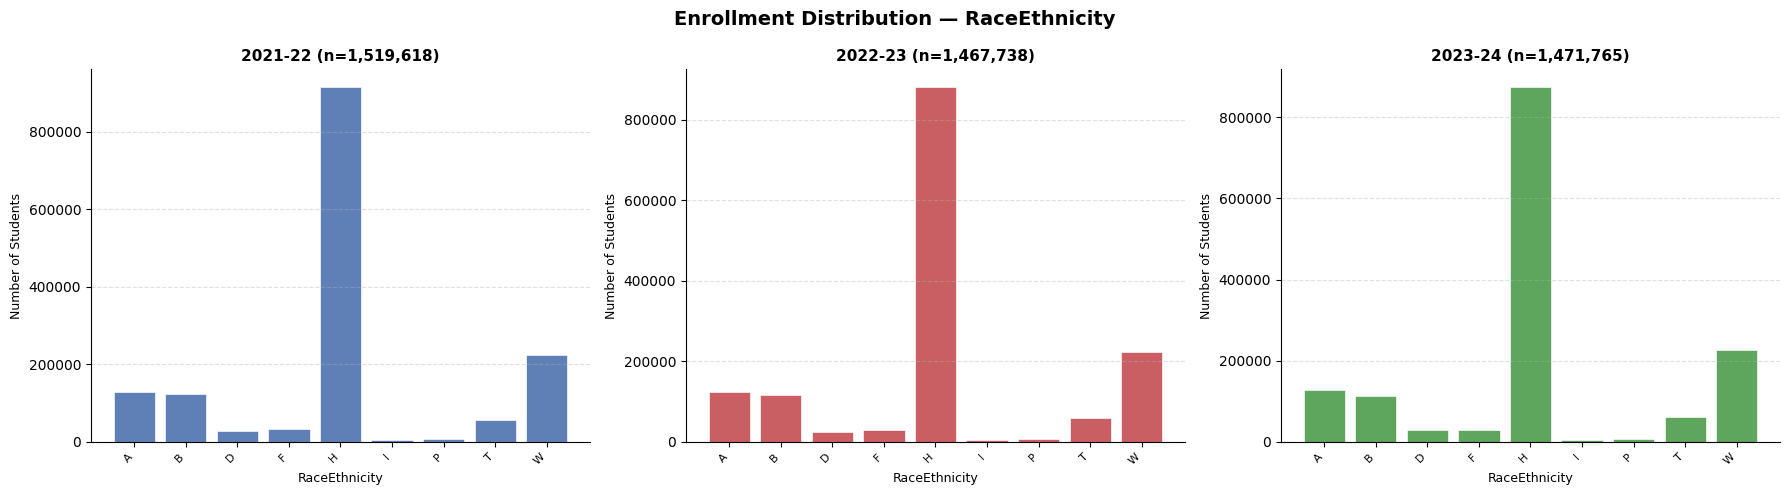

Saved enrollment_RaceEthnicity.png


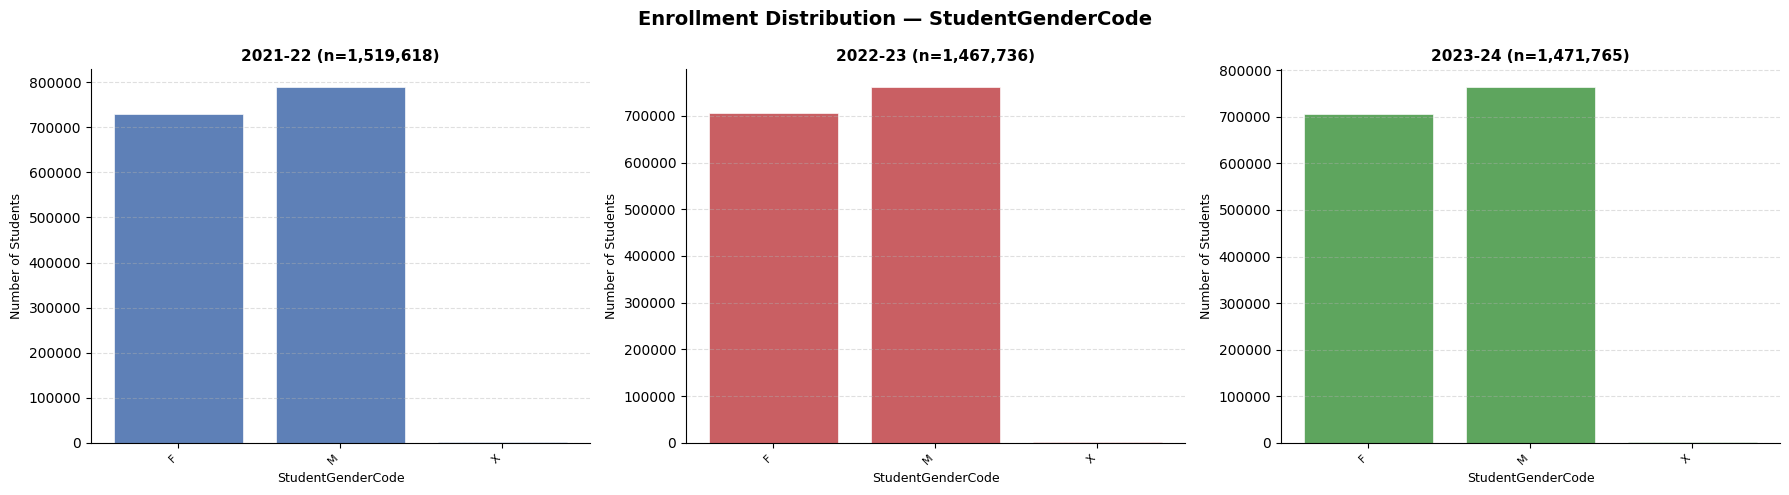

Saved enrollment_StudentGenderCode.png


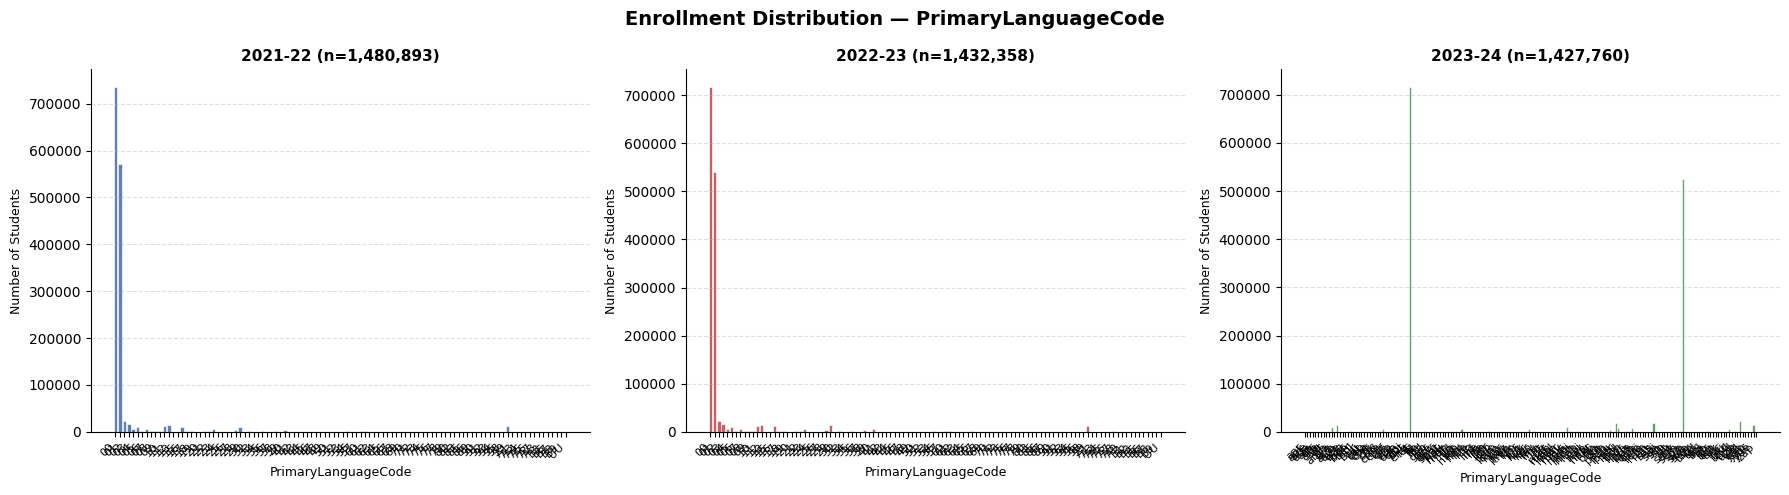

Saved enrollment_PrimaryLanguageCode.png


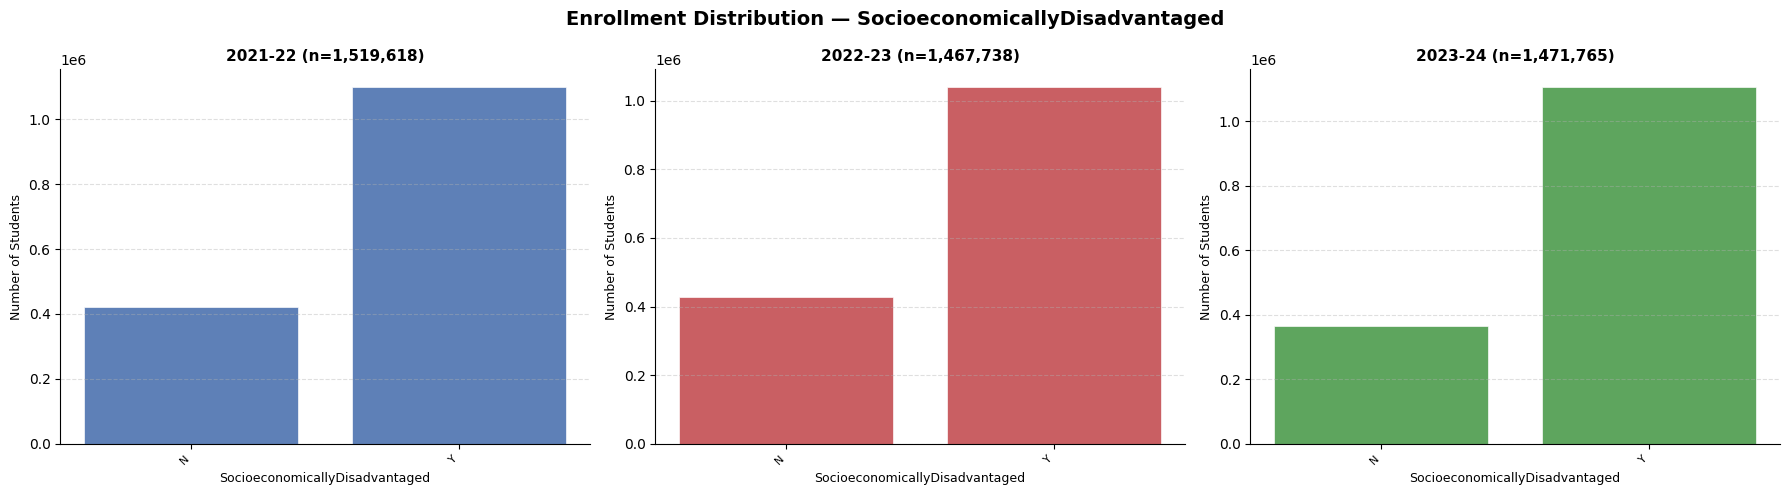

Saved enrollment_SocioeconomicallyDisadvantaged.png


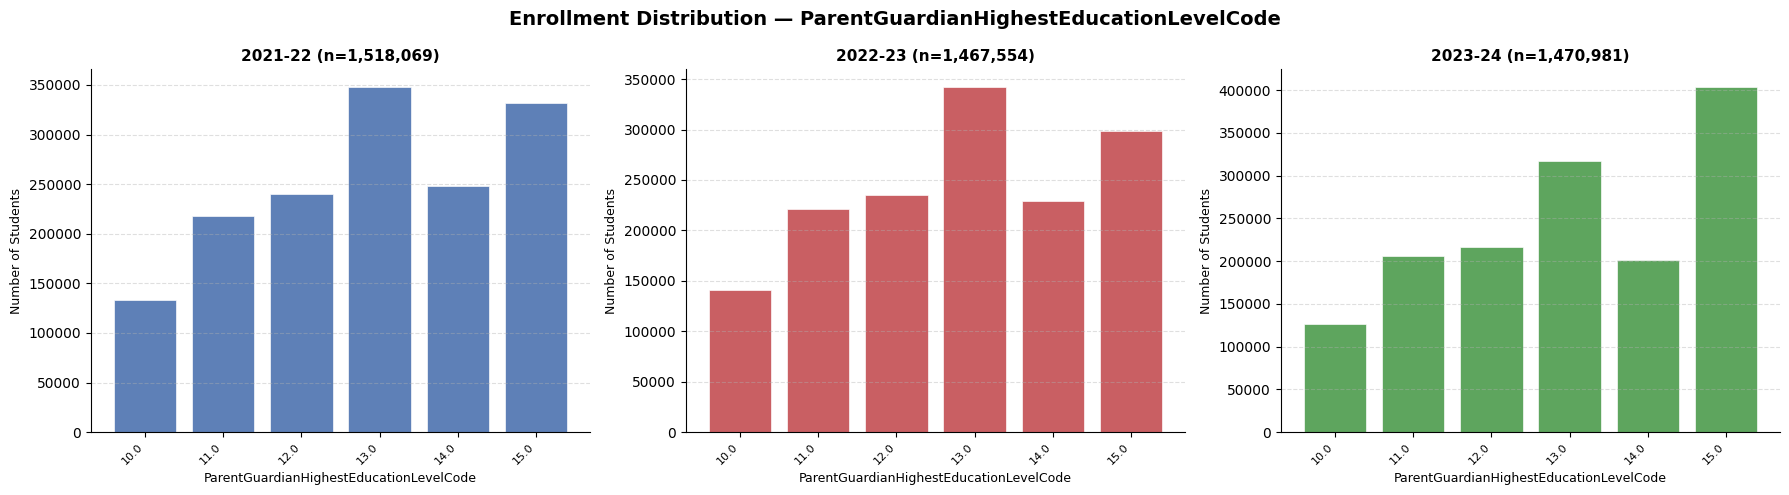

Saved enrollment_ParentGuardianHighestEducationLevelCode.png


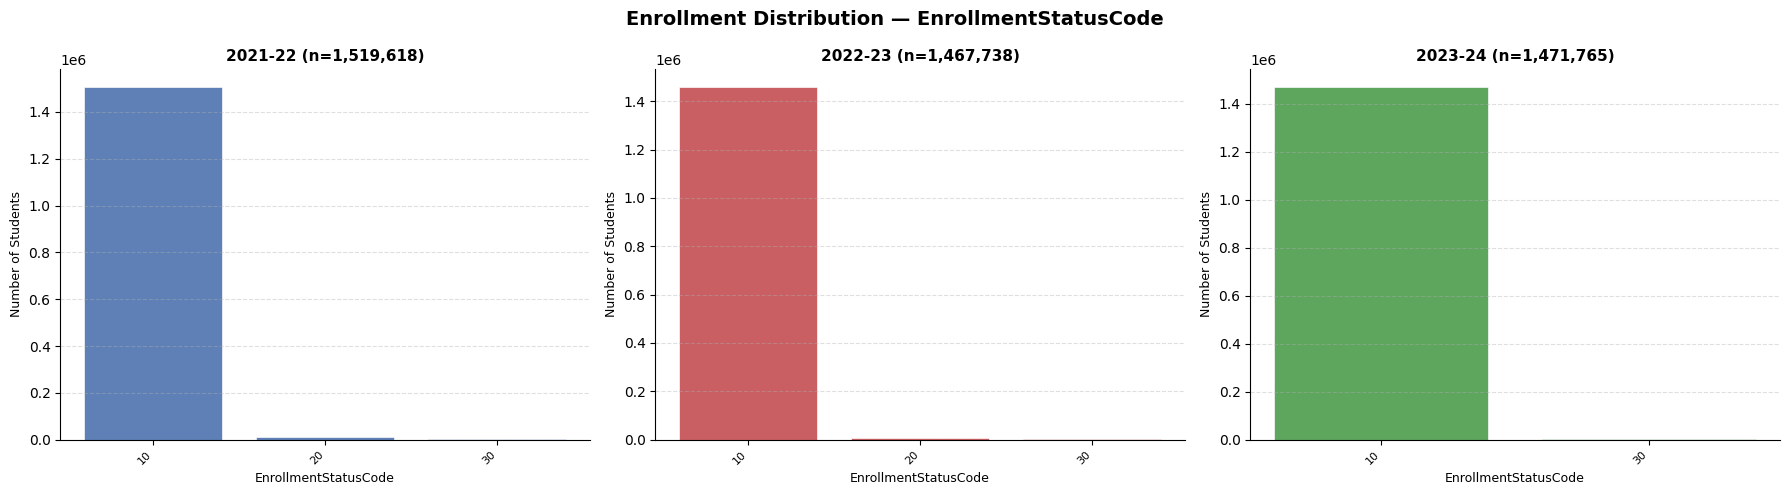

Saved enrollment_EnrollmentStatusCode.png


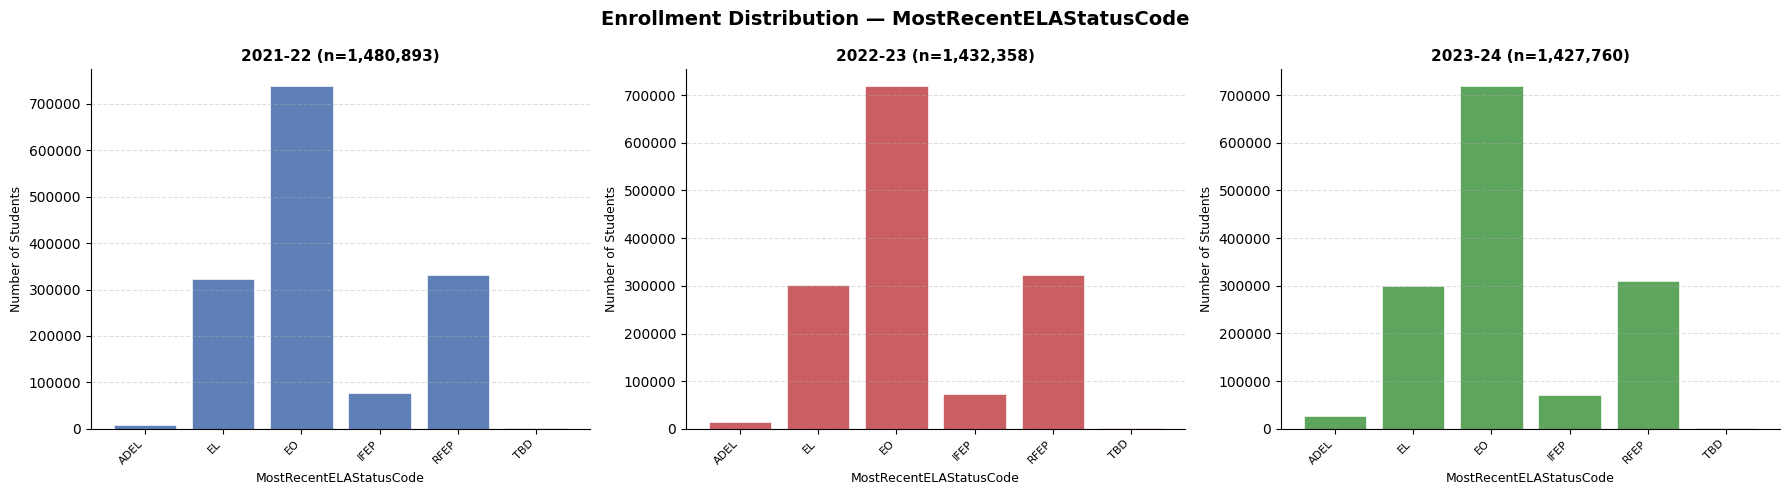

Saved enrollment_MostRecentELAStatusCode.png


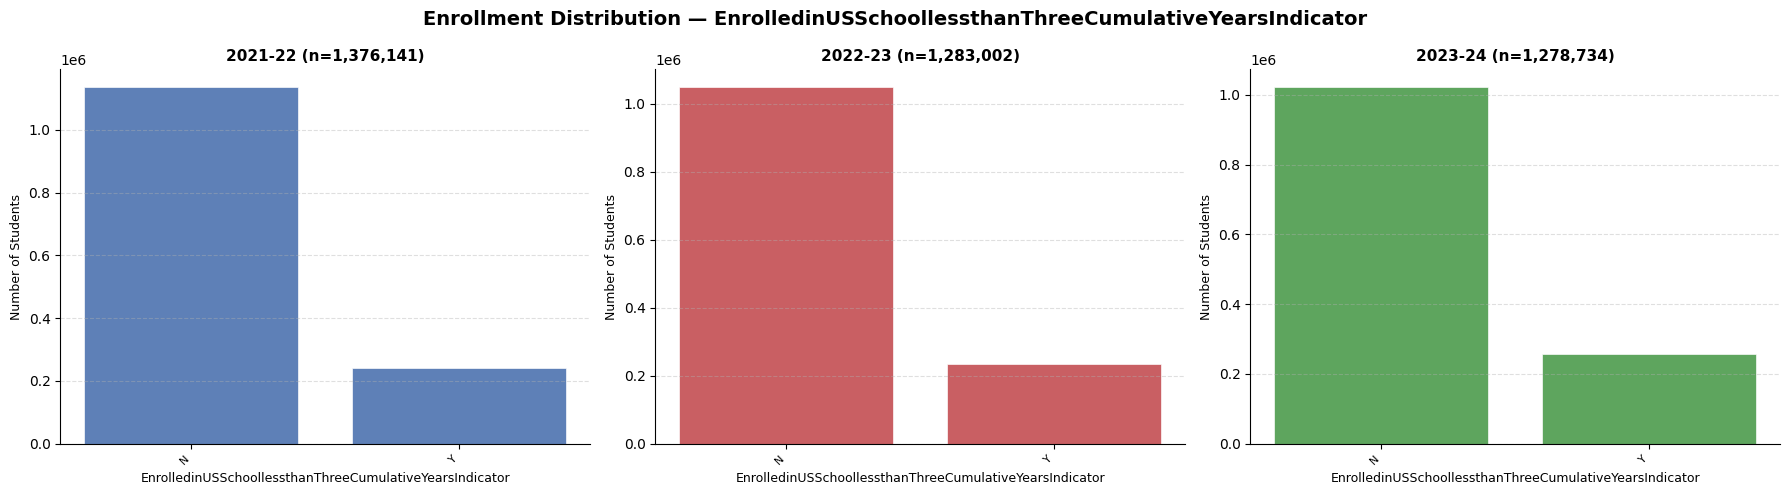

Saved enrollment_EnrolledinUSSchoollessthanThreeCumulativeYearsIndicator.png


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Load all 3 enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

data_dir = "../1095 Data/Enrollment"
enrollments = {}
for label, filename in enrollment_files.items():
    filepath = os.path.join(data_dir, filename)
    df = pd.read_csv(filepath, low_memory=False)
    enrollments[label] = df
    print(f"{label}: {len(df)} rows")

# --- Key variables to plot ---
key_vars = [
    "GradeLevelCode",
    "RaceEthnicity",
    "StudentGenderCode",
    "PrimaryLanguageCode",
    "SocioeconomicallyDisadvantaged",
    "ParentGuardianHighestEducationLevelCode",
    "EnrollmentStatusCode",
    "MostRecentELAStatusCode",
    "EnrolledinUSSchoollessthanThreeCumulativeYearsIndicator",
]

year_colors = {
    "2021-22": "#4C72B0",
    "2022-23": "#C44E52",
    "2023-24": "#4C9B4C",
}

# --- One figure per variable, with 3 subplots (one per year) ---
for var in key_vars:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Enrollment Distribution — {var}", fontsize=14, fontweight="bold")

    for ax, (year_label, df) in zip(axes, enrollments.items()):
        series = df[var].dropna().astype(str)
        value_counts = series.value_counts().sort_index()

        bars = ax.bar(
            range(len(value_counts)),
            value_counts.values,
            color=year_colors[year_label],
            edgecolor="white",
            linewidth=0.5,
            alpha=0.9
        )

        ax.set_xticks(range(len(value_counts)))
        ax.set_xticklabels(value_counts.index, rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{year_label} (n={len(series):,})", fontsize=11, fontweight="bold")
        ax.set_xlabel(var, fontsize=9)
        ax.set_ylabel("Number of Students", fontsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = var.replace("/", "_")
    plt.savefig(f"enrollment_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved enrollment_{safe_name}.png")

In [3]:
# --- PrimaryLanguageCode value counts for each year ---
print("PrimaryLanguageCode Distribution:\n")
for year_label, df in enrollments.items():
    counts = df["PrimaryLanguageCode"].dropna().astype(str).value_counts().sort_index()
    print(f"  {year_label} (n={counts.sum():,}):")
    for code, count in counts.items():
        print(f"    {code}: {count:,}")
    print()

PrimaryLanguageCode Distribution:

  2021-22 (n=1,480,893):
    00: 736,288
    01: 571,630
    02: 22,938
    03: 17,393
    04: 6,199
    05: 10,806
    06: 1,884
    07: 5,368
    08: 2,428
    09: 1,817
    10: 1,339
    11: 11,747
    12: 14,745
    13: 409
    15: 117
    16: 9,860
    17: 1,513
    18: 835
    19: 111
    20: 20
    21: 1,397
    22: 2,733
    23: 6,718
    24: 126
    25: 240
    26: 295
    27: 422
    28: 3,431
    29: 10,307
    30: 397
    32: 964
    33: 444
    34: 335
    35: 1,533
    36: 189
    37: 373
    38: 1,966
    39: 73
    40: 5,053
    41: 179
    42: 316
    43: 381
    44: 435
    45: 498
    46: 154
    47: 5
    48: 211
    49: 150
    50: 52
    51: 374
    52: 213
    53: 800
    54: 2,559
    56: 93
    57: 567
    60: 1,165
    61: 1,475
    62: 636
    63: 496
    64: 161
    65: 105
    66: 787
    67: 125
    68: 8
    69: 3
    70: 104
    71: 28
    72: 167
    73: 204
    74: 1
    75: 29
    76: 76
    77: 63
    78: 9
    79: 

In [4]:
# CALPADS Primary Language Code lookup (two-character legacy codes)
language_code_map = {
    "00": "English",
    "01": "Spanish",
    "02": "Vietnamese",
    "03": "Cantonese",
    "04": "Korean",
    "05": "Filipino (Tagalog)",
    "06": "Portuguese",
    "07": "Mandarin",
    "08": "Japanese",
    "09": "Khmer (Cambodian)",
    "10": "Lao",
    "11": "Arabic",
    "12": "Armenian",
    "13": "Burmese",
    "15": "Dutch",
    "16": "Farsi (Persian)",
    "17": "French",
    "18": "German",
    "19": "Greek",
    "20": "Chamorro (Guamanian)",
    "21": "Hebrew",
    "22": "Hindi",
    "23": "Hmong",
    "24": "Hungarian",
    "25": "Ilocano",
    "26": "Indonesian",
    "27": "Italian",
    "28": "Punjabi",
    "29": "Russian",
    "30": "Samoan",
    "32": "Thai",
    "33": "Turkish",
    "34": "Tongan",
    "35": "Urdu",
    "36": "Cebuano (Visayan)",
    "37": "Sign Languages",
    "38": "Ukrainian",
    "39": "Chaozhou (Chiuchow)",
    "40": "Pashto",
    "41": "Polish",
    "42": "Assyrian",
    "43": "Gujarati",
    "44": "Mien (Yao)",
    "45": "Rumanian",
    "46": "Taiwanese",
    "47": "Lahu",
    "48": "Marshallese",
    "49": "Mixteco",
    "50": "Khmu",
    "51": "Kurdish",
    "52": "Serbo-Croatian",
    "53": "Toishanese",
    "54": "Chaldean",
    "56": "Albanian",
    "57": "Tigrinya",
    "60": "Somali",
    "61": "Bengali",
    "62": "Telugu",
    "63": "Tamil",
    "64": "Marathi",
    "65": "Kannada",
    "66": "Amharic",
    "67": "Bulgarian",
    "68": "Kikuyu",
    "69": "Kashmiri",
    "70": "Swedish",
    "71": "Zapoteco",
    "72": "Uzbek",
    "73": "Haitian Creole",
    "74": "Kachin (Jingpho)",
    "75": "Karen languages",
    "76": "Nepali",
    "77": "Swahili",
    "78": "Oromo",
    "79": "Lingala",
    "80": "Kinyarwanda",
    "82": "Dinka",
    "83": "Afrikaans",
    "85": "Afro-Asiatic languages",
    "86": "Berber languages",
    "89": "Creoles/pidgins (English-based)",
    "90": "Creoles/pidgins (French-based)",
    "91": "Czech",
    "92": "Danish",
    "93": "Fijian",
    "94": "Finnish",
    "95": "Hawaiian",
    "98": "Other",
    "99": "Other non-English languages",
    "A1": "Iranian Languages",
    "A3": "Latvian",
    "A4": "Lithuanian",
    "A5": "Malay",
    "A6": "Malayalam",
    "A7": "Mayan Languages",
    "A8": "Mongolian",
    "B3": "Norwegian",
    "B6": "Sinhala",
    "B7": "Slovak",
    "B8": "Twi",
    "B9": "Yoruba",
    "UU": "Unknown",
}

# Print counts with language names for each year
print("PrimaryLanguageCode Distribution (with language names):\n")
for year_label, df in enrollments.items():
    counts = df["PrimaryLanguageCode"].dropna().astype(str).value_counts().sort_values(ascending=False)
    print(f"  {year_label} (n={counts.sum():,}):")
    for code, count in counts.items():
        name = language_code_map.get(code, f"Unknown code ({code})")
        print(f"    {code} - {name}: {count:,}")
    print()

PrimaryLanguageCode Distribution (with language names):

  2021-22 (n=1,480,893):
    00 - English: 736,288
    01 - Spanish: 571,630
    02 - Vietnamese: 22,938
    03 - Cantonese: 17,393
    12 - Armenian: 14,745
    99 - Other non-English languages: 12,492
    11 - Arabic: 11,747
    05 - Filipino (Tagalog): 10,806
    29 - Russian: 10,307
    16 - Farsi (Persian): 9,860
    23 - Hmong: 6,718
    04 - Korean: 6,199
    07 - Mandarin: 5,368
    40 - Pashto: 5,053
    28 - Punjabi: 3,431
    22 - Hindi: 2,733
    54 - Chaldean: 2,559
    08 - Japanese: 2,428
    38 - Ukrainian: 1,966
    06 - Portuguese: 1,884
    09 - Khmer (Cambodian): 1,817
    35 - Urdu: 1,533
    17 - French: 1,513
    61 - Bengali: 1,475
    21 - Hebrew: 1,397
    10 - Lao: 1,339
    60 - Somali: 1,165
    32 - Thai: 964
    18 - German: 835
    53 - Toishanese: 800
    66 - Amharic: 787
    UU - Unknown: 772
    62 - Telugu: 636
    57 - Tigrinya: 567
    45 - Rumanian: 498
    63 - Tamil: 496
    33 - Turkish: